# 06 · Model Development and Evaluation
**Module 7 (CO5)** — Bike Sharing Demand EDA

| Syllabus topic | Section |
|---|---|
| Constructing a linear regression model | §1–§3 |
| Evaluation, computing accuracy, understanding accuracy | §4–§6 |
| Understanding reinforcement learning; supervised vs reinforcement learning | §7 |
| Applications of reinforcement learning (with a worked example) | §8–§9 |

**Goal:** predict the **number of rentals per day** from weather and calendar information.

In [1]:
import sys
sys.path.append("../src")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from scipy import stats
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, mean_absolute_percentage_error

from utils import set_style, save_fig, load_clean_daily, load_clean_hourly, PALETTE, SEQ_CMAP

set_style()
daily = load_clean_daily()
print(daily.shape)

(731, 14)


## 1. Prepare features
Insights from the EDA notebooks guide feature choice:
- **temp** is the strongest weather driver; **atemp** is almost a copy of it (r ≈ 0.99), so we check multicollinearity with VIF.
- Demand jumped **~65% from 2011 to 2012** → include `year`.
- **Season**, **weather** and **working day** all matter → one-hot encode categories (drop one level to avoid the dummy-variable trap).
- Hot days in fall reduce demand slightly → try a **temp²** term later.

In [2]:
df = daily.copy()
df["year_2012"] = (df["year"] == 2012).astype(int)
X_all = pd.get_dummies(df[["temp", "atemp", "humidity", "windspeed", "year_2012", "workingday", "holiday",
                           "season", "weather"]],
                       columns=["season", "weather"], drop_first=True, dtype=int)
y = df["cnt"]
X_all.head()

,temp,atemp,humidity,windspeed,year_2012,workingday,holiday,season_Spring,season_Summer,season_Winter,weather_Mist/Cloudy,weather_Rain/Snow
date,,,,,,,,,,,,
2011-01-01,14.11,18.18,80.46,13.92,0,0,0,1,0,0,0,0
2011-01-02,14.90,17.68,69.61,16.65,0,0,0,1,0,0,1,0
2011-01-03,8.05,9.47,43.73,16.95,0,1,0,1,0,0,0,0
2011-01-04,8.20,10.61,59.04,11.02,0,1,0,1,0,0,0,0
2011-01-05,9.31,11.46,43.70,13.15,0,1,0,1,0,0,0,0


In [3]:
def vif_table(X):
    Xc = sm.add_constant(X)
    return pd.Series([variance_inflation_factor(Xc.values, i) for i in range(1, Xc.shape[1])],
                     index=X.columns, name="VIF").round(2)

vif_table(X_all).to_frame().T

,temp,atemp,humidity,windspeed,year_2012,workingday,holiday,season_Spring,season_Summer,season_Winter,weather_Mist/Cloudy,weather_Rain/Snow
VIF,70.43,66.6,1.64,1.19,1.03,1.08,1.07,4.55,2.04,3.05,1.3,1.29


`temp` and `atemp` have VIF ≫ 10 — severe multicollinearity, which makes their coefficients unstable. We drop `atemp`:

In [4]:
X = X_all.drop(columns="atemp")
vif_table(X).to_frame().T

,temp,humidity,windspeed,year_2012,workingday,holiday,season_Spring,season_Summer,season_Winter,weather_Mist/Cloudy,weather_Rain/Snow
VIF,3.39,1.63,1.15,1.03,1.08,1.07,4.51,1.98,2.97,1.3,1.28


## 2. Simple linear regression from scratch
Model: $\hat y = \beta_0 + \beta_1 x$. Least squares solution: $\beta_1 = \frac{\sum (x-\bar x)(y-\bar y)}{\sum (x-\bar x)^2}$, $\beta_0 = \bar y - \beta_1\bar x$.

cnt = 1215.5 + 161.9 × temp     (R² = 0.394)


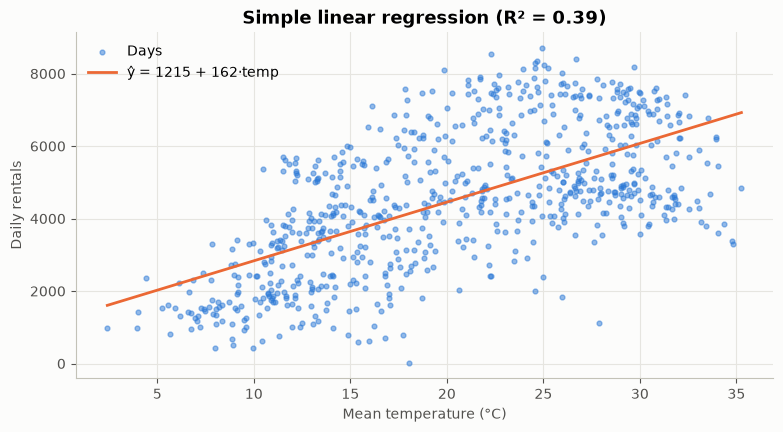

In [5]:
x = df["temp"].values
b1 = np.sum((x - x.mean()) * (y - y.mean())) / np.sum((x - x.mean()) ** 2)
b0 = y.mean() - b1 * x.mean()
y_hat = b0 + b1 * x
r2_simple = 1 - np.sum((y - y_hat) ** 2) / np.sum((y - y.mean()) ** 2)
print(f"cnt = {b0:.1f} + {b1:.1f} × temp     (R² = {r2_simple:.3f})")

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.scatter(x, y, s=12, alpha=0.5, color=PALETTE[0], label="Days")
xs = np.linspace(x.min(), x.max(), 100)
ax.plot(xs, b0 + b1 * xs, color=PALETTE[1], label=f"ŷ = {b0:.0f} + {b1:.0f}·temp")
ax.set_xlabel("Mean temperature (°C)")
ax.set_ylabel("Daily rentals")
ax.set_title(f"Simple linear regression (R² = {r2_simple:.2f})")
ax.legend()
save_fig(fig, "06_simple_regression")
plt.show()

Each extra °C is associated with about **+160 rentals per day**, but temperature alone explains only ~39% of the variation.

## 3. Multiple linear regression
We hold out 20% of days as a **test set** that the model never sees during training.

In [6]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("train:", X_train.shape, "| test:", X_test.shape)

ols = sm.OLS(y_train, sm.add_constant(X_train)).fit()
print(ols.summary())

train: (584, 11) | test: (147, 11)
                            OLS Regression Results                            
Dep. Variable:                    cnt   R-squared:                       0.823
Model:                            OLS   Adj. R-squared:                  0.820
Method:                 Least Squares   F-statistic:                     241.9
Date:                Fri, 30 Oct 2026   Prob (F-statistic):          7.02e-207
Time:                        14:38:19   Log-Likelihood:                -4736.4
No. Observations:                 584   AIC:                             9497.
Df Residuals:                     572   BIC:                             9549.
Df Model:                          11                                         
Covariance Type:            nonrobust                                         
                          coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------

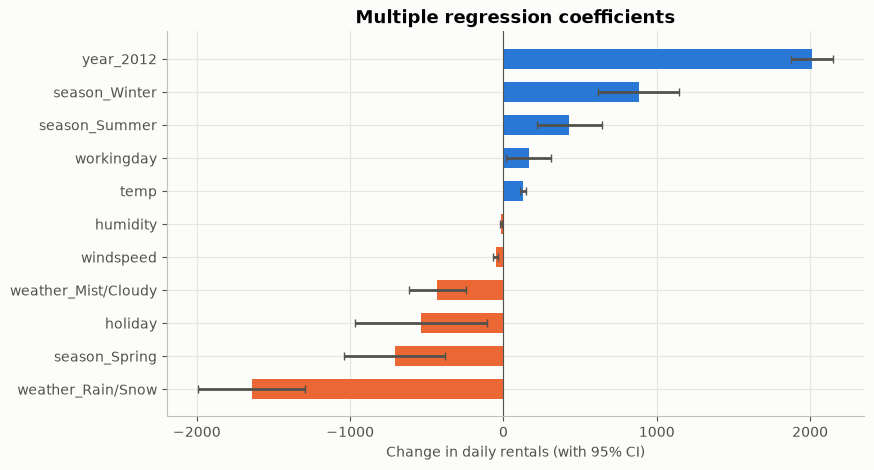

In [7]:
coef = ols.params.drop("const").sort_values()
colors = [PALETTE[1] if c < 0 else PALETTE[0] for c in coef]
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(coef.index, coef.values, color=colors, height=0.6)
ax.errorbar(coef.values, coef.index, xerr=1.96 * ols.bse[coef.index], fmt="none", ecolor="#52514e", capsize=3)
ax.axvline(0, color="#52514e", linewidth=0.8)
ax.set_xlabel("Change in daily rentals (with 95% CI)")
ax.set_title("Multiple regression coefficients")
save_fig(fig, "06_coefficients")
plt.show()

**Reading the coefficients** (each holds the other variables constant; season baseline = Fall, weather baseline = Clear):
- **year_2012 ≈ +2,000 rides/day** — growth of the system.
- **temp ≈ +128 rides per °C** (smaller than in the simple model, because season and year now share the credit).
- **Rain/Snow ≈ −1,640** and **Mist/Cloudy ≈ −430** rides vs a clear day.
- Humidity (−14 per %) and windspeed (−49 per km/h) reduce demand.
- **Spring ≈ −710** vs Fall, while **Winter ≈ +880** at the *same temperature*: a mild winter day attracts more riders than a fall day of equal temperature.
- All p-values are < 0.05, so every predictor is statistically significant. `holiday` (≈ −540) and `workingday` (≈ +160) have the widest confidence intervals.
- R² ≈ 0.82 on training data; the Durbin–Watson statistic ≈ 2 suggests no strong autocorrelation in the residuals.

## 4. Evaluation and computing accuracy
For **regression** there is no single "accuracy". We use several complementary metrics:

| Metric | Formula | Meaning |
|---|---|---|
| MAE | $\frac1n\sum\lvert y-\hat y\rvert$ | average error in rides |
| RMSE | $\sqrt{\frac1n\sum (y-\hat y)^2}$ | penalises big errors more |
| R² | $1-\frac{SS_{res}}{SS_{tot}}$ | share of variance explained |
| Adjusted R² | $1-(1-R^2)\frac{n-1}{n-p-1}$ | R² penalised for extra features |
| MAPE | $\frac{100}{n}\sum\lvert\frac{y-\hat y}{y}\rvert$ | average % error |
| Accuracy ±x% | share of predictions within x% of truth | an intuitive "hit rate" |

In [8]:
def evaluate(y_true, y_pred, p):
    n = len(y_true)
    r2 = r2_score(y_true, y_pred)
    ape = np.abs((y_true - y_pred) / y_true)
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R²": r2,
        "Adj. R²": 1 - (1 - r2) * (n - 1) / (n - p - 1),
        "MAPE (%)": mean_absolute_percentage_error(y_true, y_pred) * 100,
        "Median APE (%)": np.median(ape) * 100,
        "Within ±10% (%)": (ape <= 0.10).mean() * 100,
        "Within ±20% (%)": (ape <= 0.20).mean() * 100,
    }

lr = LinearRegression().fit(X_train, y_train)
pred_train, pred_test = lr.predict(X_train), lr.predict(X_test)
baseline = np.full(len(y_test), y_train.mean())   # always predict the training mean

results = pd.DataFrame({
    "Baseline (mean) — test": evaluate(y_test, baseline, 0),
    "Linear model — train": evaluate(y_train, pred_train, X.shape[1]),
    "Linear model — test": evaluate(y_test, pred_test, X.shape[1]),
}).T.round(3)
results

,MAE,RMSE,R²,Adj. R²,MAPE (%),Median APE (%),Within ±10% (%),Within ±20% (%)
Baseline (mean) — test,1711.991,2022.173,-0.020,-0.020,202.371,35.260,15.646,31.973
Linear model — train,592.299,805.343,0.823,0.820,18.355,10.046,49.658,75.000
Linear model — test,577.535,764.939,0.854,0.842,130.612,10.941,44.218,72.109


In [9]:
# 5-fold cross-validation gives a more reliable estimate than one split
cv = KFold(5, shuffle=True, random_state=0)
cv_r2 = cross_val_score(LinearRegression(), X, y, cv=cv, scoring="r2")
cv_mae = -cross_val_score(LinearRegression(), X, y, cv=cv, scoring="neg_mean_absolute_error")
print("CV R²  per fold:", cv_r2.round(3), "→ mean", cv_r2.mean().round(3), "± ", cv_r2.std().round(3))
print("CV MAE per fold:", cv_mae.round(0), "→ mean", cv_mae.mean().round(0))

CV R²  per fold: [0.834 0.816 0.826 0.827 0.809] → mean 0.822 ±  0.009
CV MAE per fold: [628. 593. 605. 615. 575.] → mean 603.0


## 5. Residual diagnostics
Linear regression assumes residuals are roughly **normal**, have **constant variance** and show **no pattern**.

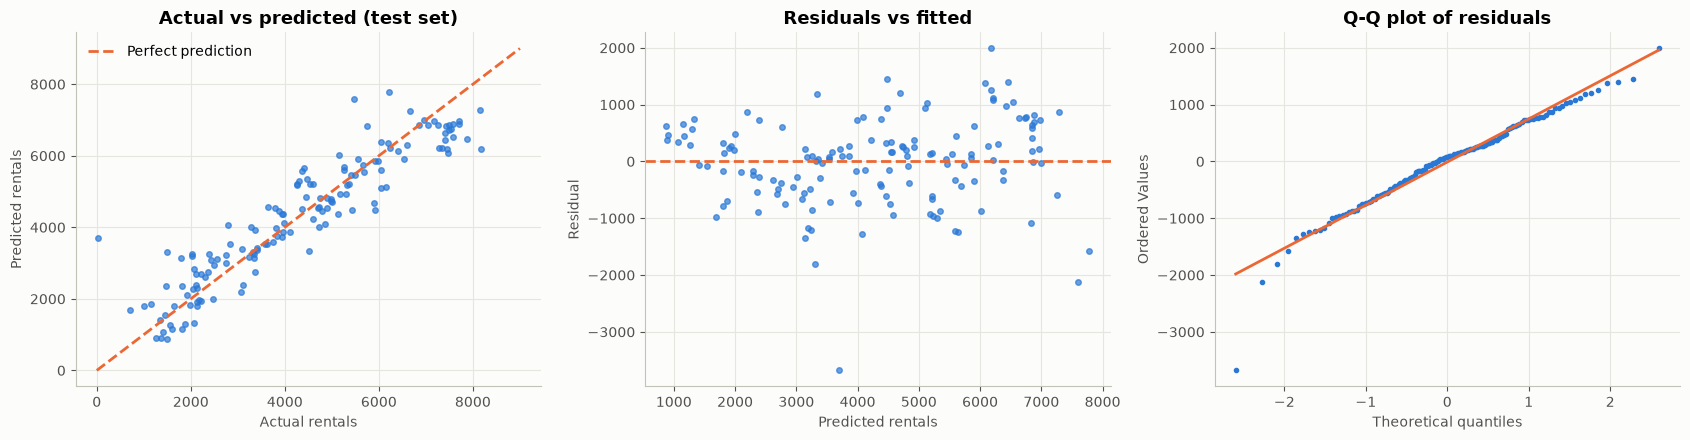

In [10]:
resid = y_test - pred_test
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
axes[0].scatter(y_test, pred_test, s=16, alpha=0.7, color=PALETTE[0])
lims = [0, 9000]
axes[0].plot(lims, lims, color=PALETTE[1], linestyle="--", label="Perfect prediction")
axes[0].set_xlabel("Actual rentals")
axes[0].set_ylabel("Predicted rentals")
axes[0].set_title("Actual vs predicted (test set)")
axes[0].legend()

axes[1].scatter(pred_test, resid, s=16, alpha=0.7, color=PALETTE[0])
axes[1].axhline(0, color=PALETTE[1], linestyle="--")
axes[1].set_xlabel("Predicted rentals")
axes[1].set_ylabel("Residual")
axes[1].set_title("Residuals vs fitted")

stats.probplot(resid, dist="norm", plot=axes[2])
axes[2].get_lines()[0].set(color=PALETTE[0], markersize=3)
axes[2].get_lines()[1].set(color=PALETTE[1])
axes[2].set_title("Q-Q plot of residuals")
fig.tight_layout()
save_fig(fig, "06_residuals")
plt.show()

In [11]:
# Which days does the model get most wrong? (fit on all days to inspect every date)
full_pred = LinearRegression().fit(X, y).predict(X)
err = pd.DataFrame({"actual": y, "predicted": full_pred.round(0), "residual": (y - full_pred).round(0),
                    "weather": df["weather"], "holiday": df["holiday"]})
err.sort_values("residual").head(6)

,actual,predicted,residual,weather,holiday
date,,,,,
2012-10-29,22,3444.0,-3422.0,Rain/Snow,0
2012-11-22,2425,5345.0,-2920.0,Clear,1
2012-07-07,4840,7741.0,-2901.0,Clear,0
2012-05-14,2843,5728.0,-2885.0,Mist/Cloudy,0
2012-11-25,2424,5295.0,-2871.0,Clear,0
2012-07-08,4672,7484.0,-2812.0,Clear,0


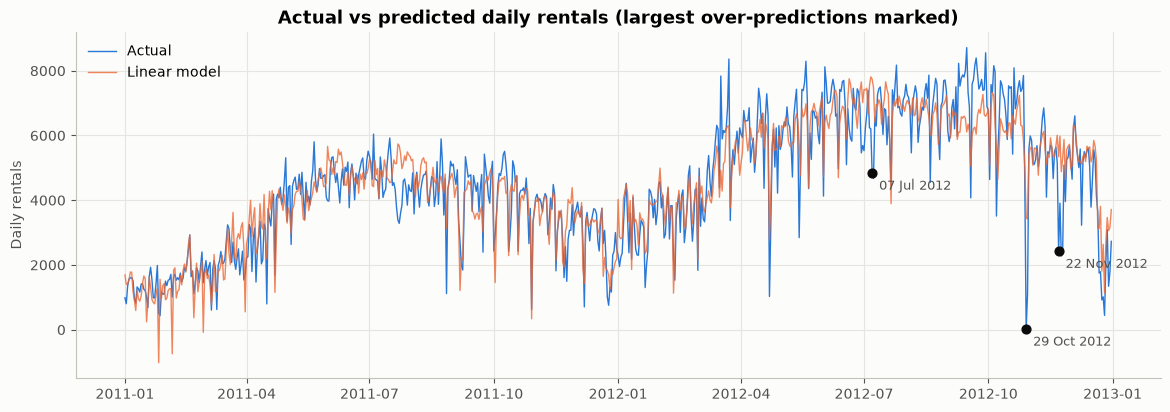

In [12]:
fig, ax = plt.subplots(figsize=(14, 4.5))
ax.plot(y.index, y, color=PALETTE[0], linewidth=1, label="Actual")
ax.plot(y.index, full_pred, color=PALETTE[1], linewidth=1, alpha=0.8, label="Linear model")
worst = err.nsmallest(3, "residual")
ax.scatter(worst.index, worst["actual"], color="#0b0b0b", s=40, zorder=3)
for d in worst.index:
    ax.annotate(d.strftime("%d %b %Y"), (d, y[d]), xytext=(5, -12), textcoords="offset points",
                fontsize=9, color="#52514e")
ax.set_ylabel("Daily rentals")
ax.set_title("Actual vs predicted daily rentals (largest over-predictions marked)")
ax.legend(loc="upper left")
save_fig(fig, "06_prediction_timeline")
plt.show()

The largest over-predictions are explainable:
- **29 Oct 2012 — Hurricane Sandy:** the model expects a normal rainy day (~3,400 rides), but the city was shut down (22 rides). The clustering methods in notebook 04 missed this day; the regression **residual** catches it.
- **22 Nov 2012 — Thanksgiving**, plus the following weekend.
- **7–8 Jul 2012 — record heat wave** (around 40 °C). A linear temperature term predicts *more* riders on hotter days, but extreme heat keeps people indoors; the next section fixes this.

## 6. Improving the model and understanding accuracy
Scatter plots showed demand **levels off / falls on very hot days**, which a straight line cannot capture. Adding **temp²** lets the model bend.

In [13]:
def fit_eval(features, name):
    Xtr, Xte = X_train[features], X_test[features]
    m = LinearRegression().fit(Xtr, y_train)
    r = evaluate(y_test, m.predict(Xte), len(features))
    r["CV R² (5-fold)"] = cross_val_score(LinearRegression(), X[features], y, cv=cv, scoring="r2").mean()
    return pd.Series(r, name=name)

X["temp_sq"] = X["temp"] ** 2
X_train, X_test = X.loc[X_train.index], X.loc[X_test.index]
base_feats = [c for c in X.columns if c != "temp_sq"]

comparison = pd.DataFrame([
    fit_eval(["temp"], "1. temp only"),
    fit_eval(["temp", "year_2012"], "2. + year"),
    fit_eval(base_feats, "3. all features"),
    fit_eval(base_feats + ["temp_sq"], "4. all + temp²"),
]).round(3)
comparison

,MAE,RMSE,R²,Adj. R²,MAPE (%),Median APE (%),Within ±10% (%),Within ±20% (%),CV R² (5-fold)
1. temp only,1291.978,1546.232,0.404,0.400,168.940,30.114,19.728,34.694,0.392
2. + year,836.774,1072.659,0.713,0.709,183.824,18.368,31.293,53.741,0.681
3. all features,577.535,764.939,0.854,0.842,130.612,10.941,44.218,72.109,0.822
4. all + temp²,537.304,709.607,0.874,0.863,129.483,9.419,53.061,75.510,0.851


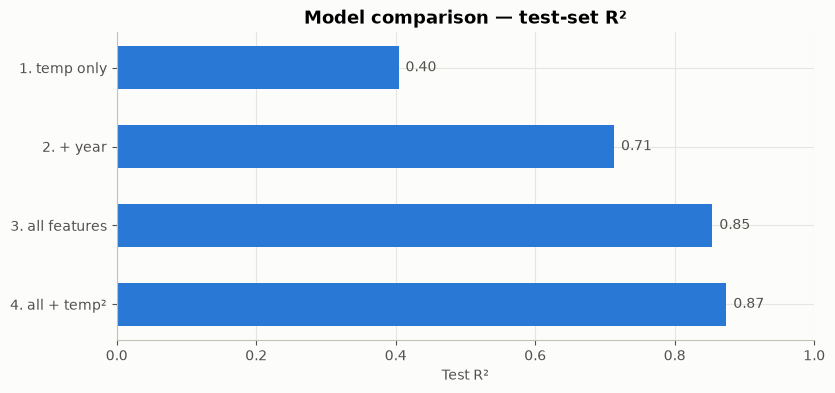

In [14]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(comparison.index[::-1], comparison["R²"][::-1], color=PALETTE[0], height=0.55)
for i, v in enumerate(comparison["R²"][::-1]):
    ax.text(v + 0.01, i, f"{v:.2f}", va="center", color="#52514e")
ax.set_xlim(0, 1)
ax.set_xlabel("Test R²")
ax.set_title("Model comparison — test-set R²")
save_fig(fig, "06_model_comparison")
plt.show()

### Understanding accuracy
- Adding **temp²** improves every metric (test R² 0.85 → 0.87, CV R² 0.82 → 0.85), confirming the curved temperature effect seen in the EDA.
- **R² ≈ 0.87** means the model explains about 87% of the day-to-day variation in rentals. The rest comes from things it cannot see (events, storms, hourly weather changes).
- **MAE ≈ 540 rides** sounds large, but it is only ~12% of an average day (~4,500 rides). Always compare errors with the **scale** of the target and with a **baseline**: the mean-only model's MAE (≈ 1,700) is about 3× higher, and its R² is ≈ 0.
- **MAPE is misleading** when actual values can be tiny. The test set contains Hurricane Sandy (22 rides), and that one day pushes MAPE above 100%. The **median APE (≈ 9%)** and the **"within ±20%" hit rate (≈ 76%)** are more robust summaries.
- **Train vs test:** similar scores on both mean the model is **not overfitting**. A much better train score would signal overfitting.
- **Cross-validation** averages over 5 different splits, so a single lucky split cannot inflate the result.
- "Accuracy" in the classification sense (% correct labels) only applies if we turn the problem into classes, e.g. predicting *demand level* (Low / Medium / High). For a continuous target we report error metrics instead.

In [15]:
# Accuracy in the classification sense: bin predictions into demand levels and compare
model = LinearRegression().fit(X_train[base_feats + ["temp_sq"]], y_train)
pred = model.predict(X_test[base_feats + ["temp_sq"]])
edges = [-np.inf, 3000, 5500, np.inf]
labels = ["Low", "Medium", "High"]
true_cls = pd.cut(y_test, edges, labels=labels)
pred_cls = pd.cut(pred, edges, labels=labels)
print(f"Classification accuracy (Low <3000 / Medium / High >5500): {(true_cls == pred_cls).mean() * 100:.1f}%")
pd.crosstab(pd.Series(true_cls, name="actual", index=y_test.index),
            pd.Series(pred_cls, name="predicted", index=y_test.index))

Classification accuracy (Low <3000 / Medium / High >5500): 85.7%


predicted,Low,Medium,High
actual,,,
Low,36,9,0
Medium,2,54,5
High,0,5,36


## 7. Understanding reinforcement learning (RL)
In **reinforcement learning** an **agent** learns by **interacting with an environment**. At each step it observes a **state**, takes an **action**, and receives a **reward**. Its goal is a **policy** (state → action) that maximises the total future reward.

### Supervised vs reinforcement learning

| Aspect | Supervised learning (e.g. our regression) | Reinforcement learning |
|---|---|---|
| Data | Fixed dataset of (input, correct output) pairs | Generated by the agent's own actions |
| Feedback | The **correct answer** for every example | Only a **reward signal** (how good, not what is right), often delayed |
| Goal | Minimise prediction error | Maximise cumulative reward |
| Decisions | Each prediction is independent | Actions affect future states (sequential) |
| Exploration | Not needed | Must balance **exploration vs exploitation** |
| Example here | Predict tomorrow's rentals | Decide *when to move bikes* between stations |

**Key RL terms:** state *s*, action *a*, reward *r*, policy π, discount factor γ, value function, **Q-value** *Q(s, a)* = expected future reward from taking *a* in *s*.

**Q-learning update:** $Q(s,a) \leftarrow Q(s,a) + \alpha\,[\,r + \gamma \max_{a'} Q(s',a') - Q(s,a)\,]$

## 8. Worked example: Q-learning for bike rebalancing
A real operational problem: a **residential docking station** loses bikes in the morning (people ride to work) and gains them back in the evening. If it is **empty**, riders cannot rent; if it is **full**, riders cannot return. A truck can add or remove bikes, but each trip costs money.

**Environment (built from the real data):**
- Station capacity **20 bikes**, starts each day with 10. One episode = one working day (24 hourly steps).
- Hourly demand follows the **real average working-day profile** from this dataset, scaled down to one station.
- Morning hours: 75% of activity are pick-ups; evening: 75% are returns.
- **Actions:** 0 = do nothing, 1 = truck adds 5 bikes, 2 = truck removes 5 bikes.
- **Reward:** +1 per served pick-up, −3 per rider who finds no bike, −3 per rider who finds no free dock, −4 per truck trip.

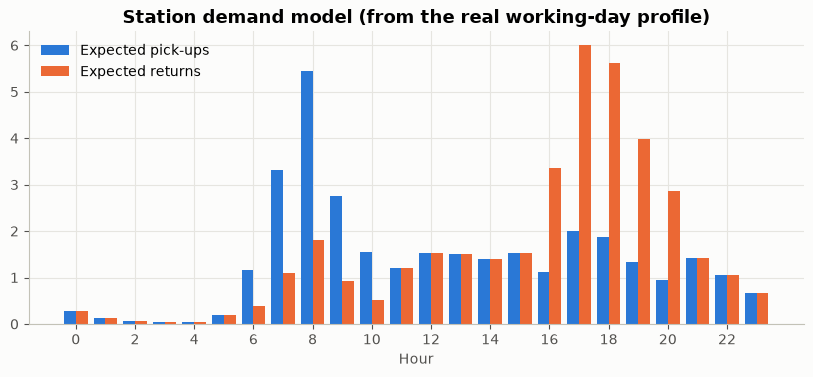

In [16]:
hourly = load_clean_hourly()
work_profile = hourly[hourly.workingday == 1].groupby("hour")["cnt"].mean().values
activity = work_profile / work_profile.max() * 8          # peak hour ≈ 8 movements at this station
pick_share = np.full(24, 0.5)
pick_share[6:11] = 0.75                                    # morning: people leave home
pick_share[16:21] = 0.25                                   # evening: people come back
lam_pick, lam_ret = activity * pick_share, activity * (1 - pick_share)

CAP, START, MOVE = 20, 10, 5
ACTIONS = {0: 0, 1: +MOVE, 2: -MOVE}

def step(bikes, hour, action, rng):
    """Apply the truck action, then one hour of random pick-ups and returns."""
    reward = -4 if action != 0 else 0
    bikes = int(np.clip(bikes + ACTIONS[action], 0, CAP))
    picks, rets = rng.poisson(lam_pick[hour]), rng.poisson(lam_ret[hour])
    served = min(picks, bikes)
    bikes -= served
    docked = min(rets, CAP - bikes)
    bikes += docked
    reward += served - 3 * (picks - served) - 3 * (rets - docked)
    return bikes, reward, picks - served, rets - docked

def run_day(policy, rng):
    bikes, total, lost = START, 0, 0
    for h in range(24):
        a = policy(h, bikes)
        bikes, r, no_bike, no_dock = step(bikes, h, a, rng)
        total += r
        lost += no_bike + no_dock
    return total, lost

fig, ax = plt.subplots(figsize=(10, 3.8))
ax.bar(np.arange(24) - 0.2, lam_pick, width=0.4, color=PALETTE[0], label="Expected pick-ups")
ax.bar(np.arange(24) + 0.2, lam_ret, width=0.4, color=PALETTE[1], label="Expected returns")
ax.set_xticks(range(0, 24, 2))
ax.set_xlabel("Hour")
ax.set_title("Station demand model (from the real working-day profile)")
ax.legend()
save_fig(fig, "06_rl_environment")
plt.show()

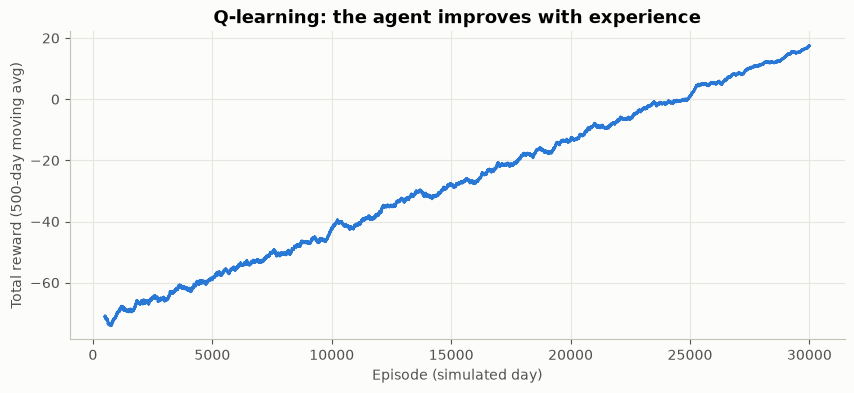

In [17]:
# Q-learning
rng = np.random.default_rng(0)
Q = np.zeros((24, CAP + 1, 3))
alpha, gamma = 0.1, 0.95
episodes = 30000
eps_schedule = np.linspace(1.0, 0.02, episodes)   # explore a lot at first, then exploit
returns = []

for ep in range(episodes):
    bikes, total = START, 0
    eps = eps_schedule[ep]
    for h in range(24):
        a = rng.integers(3) if rng.random() < eps else int(np.argmax(Q[h, bikes]))
        new_bikes, r, *_ = step(bikes, h, a, rng)
        target = r + (gamma * Q[h + 1, new_bikes].max() if h < 23 else 0)
        Q[h, bikes, a] += alpha * (target - Q[h, bikes, a])
        bikes, total = new_bikes, total + r
    returns.append(total)

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(pd.Series(returns).rolling(500).mean(), color=PALETTE[0])
ax.set_xlabel("Episode (simulated day)")
ax.set_ylabel("Total reward (500-day moving avg)")
ax.set_title("Q-learning: the agent improves with experience")
save_fig(fig, "06_rl_learning_curve")
plt.show()

In [18]:
# Compare the learned policy with simple baselines on 2,000 new simulated days
policies = {
    "Never rebalance": lambda h, b: 0,
    "Random actions": lambda h, b, r=np.random.default_rng(1): int(r.integers(3)),
    "Rule of thumb (fix at 7 AM & 4 PM)": lambda h, b: 1 if (h == 7 and b < 10) else (2 if (h == 16 and b > 10) else 0),
    "Q-learning policy": lambda h, b: int(np.argmax(Q[h, b])),
}
rows = []
for name, pol in policies.items():
    rng_eval = np.random.default_rng(123)
    res = np.array([run_day(pol, rng_eval) for _ in range(2000)])
    rows.append({"policy": name, "mean daily reward": res[:, 0].mean(), "riders turned away / day": res[:, 1].mean()})
pd.DataFrame(rows).set_index("policy").round(2)

,mean daily reward,riders turned away / day
policy,,
Never rebalance,8.53,6.68
Random actions,-72.24,11.67
Rule of thumb (fix at 7 AM & 4 PM),12.21,5.15
Q-learning policy,20.13,0.63


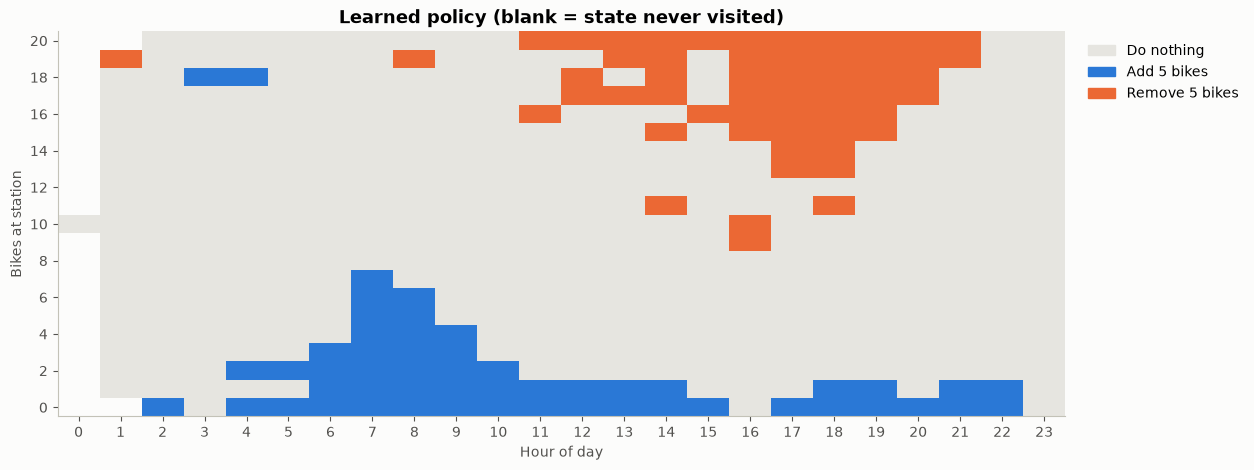

In [19]:
policy_map = np.argmax(Q, axis=2).T          # bikes × hour
visited = (Q != 0).any(axis=2).T
fig, ax = plt.subplots(figsize=(13, 5))
cmap = plt.matplotlib.colors.ListedColormap(["#e6e5e0", PALETTE[0], PALETTE[1]])
ax.imshow(np.where(visited, policy_map, np.nan), cmap=cmap, aspect="auto", origin="lower", vmin=0, vmax=2)
ax.set_xticks(range(24))
ax.set_yticks(range(0, CAP + 1, 2))
ax.set_xlabel("Hour of day")
ax.set_ylabel("Bikes at station")
ax.set_title("Learned policy (blank = state never visited)")
ax.grid(False)
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in ["#e6e5e0", PALETTE[0], PALETTE[1]]]
ax.legend(handles, ["Do nothing", "Add 5 bikes", "Remove 5 bikes"], loc="upper left",
          bbox_to_anchor=(1.01, 1), frameon=False)
save_fig(fig, "06_rl_policy")
plt.show()

**What the agent learned** — with no labelled examples, only rewards:
- **Add bikes** before and during the morning peak when the station is running low.
- **Remove bikes** before and during the evening return wave when the station is filling up.
- **Do nothing** most of the time, because each truck trip costs reward.

On 2,000 new simulated days it turns away **~0.6 riders per day**, vs ~6.7 when never rebalancing and ~5.2 with a hand-written rule, and it earns the highest reward. That is the RL idea in miniature: the "correct action" was never given; it was discovered through trial and error.

## 9. Applications of reinforcement learning

| Domain | Example | State → Action → Reward |
|---|---|---|
| **Bike/scooter sharing** | Rebalancing trucks; rider incentives (e.g. paying riders to return bikes to empty stations) | station levels → move bikes / set incentive → served trips − costs |
| **Ride-hailing & logistics** | Dispatching drivers, routing deliveries | demand map → assign vehicle → completed trips, fuel cost |
| **Dynamic pricing** | Airline, hotel and e-commerce prices | demand, inventory → set price → revenue |
| **Games** | AlphaGo, Atari, chess engines | board → move → win/loss |
| **Robotics** | Walking, grasping, drone control | sensor readings → motor commands → task success |
| **Traffic signal control** | Adaptive traffic lights | queue lengths → phase timing → lower waiting time |
| **Recommender systems** | News feed, video recommendations | user history → item shown → clicks, watch time |
| **Energy** | Data-centre cooling, smart grids | temperatures, load → cooling settings → energy saved |
| **Finance** | Portfolio allocation, trade execution | market state → buy/sell → risk-adjusted return |
| **Healthcare** | Personalised treatment dosing | patient state → dose → health outcome |
| **Large language models** | RL from human feedback (RLHF) to make chatbots helpful | prompt → response → human-preference reward |

**When to use RL instead of supervised learning:** when the task is a **sequence of decisions**, actions **change the future**, and you can define a reward but cannot easily label the "right" answer.

## Summary
- Built linear regression step by step: simple regression from scratch → multiple regression with statsmodels → VIF check (dropped `atemp`) → `temp²` term.
- The final model explains about **87% of test-set variance** (85% cross-validated), has a mean absolute error of about **540 rides/day** (~12% of an average day), and does not overfit (similar train, test and cross-validated scores). Binned into Low/Medium/High demand it is **~86% accurate**.
- "Accuracy" for regression means comparing MAE/RMSE/R² against a baseline and the target's scale; MAPE is unstable when actual values are tiny (storm days).
- Residual analysis pinpointed **Hurricane Sandy**, Thanksgiving and the July 2012 heat wave.
- **Reinforcement learning** differs from supervised learning: it learns from rewards through interaction. A Q-learning agent trained on a station model built from the real demand profile learned a sensible rebalancing policy on its own.